# 05 - Retraining and monitoring

Replaying the last three backtest periods week by week with three ways of keeping the model up to date, to see how the error, the coverage of the band and the cost of the decision change as the model ages. It is a simulation on past data and not a deployed monitor.

## Part 1. Setup

The window is the 168 days of the three backtest periods, split in 24 weeks. In each week the forecast is made with the model that would have been in use at that time. Three strategies are compared, never retraining after the first week, retraining every four weeks and retraining every week.

A model retrained on a given day is trained on the days before the 56 days that precede it and calibrated on those 56 days, the same procedure as the backtest, and the Black Friday weeks are left out of training.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from olist_forecast import build_features, load_series
from olist_forecast.monitoring import STRATEGIES, default_window, replay, summarize

long = build_features(load_series("../data/processed/demand_daily.csv"))
first_day, last_day = default_window(long)
print("window", first_day.date(), "to", last_day.date())
print("weeks between retrainings", STRATEGIES)

window 2018-03-07 to 2018-08-21
weeks between retrainings {'never': None, 'every_4_weeks': 4, 'weekly': 1}


### Replay

Costs are the same assumed values as in notebook 04, a missing unit costs 4 and an idle unit costs 1.

In [2]:
CU, CO = 4.0, 1.0

results = replay(long, CU, CO)
summary = summarize(results)
summary.round(3).reset_index()

,strategy,retrainings,wape_model,wape_baseline,coverage,cost_model,cost_baseline_buffer,saving_vs_buffer,alert_weeks,weeks
0,never,1,0.368,0.351,0.833,19414.548,18563.500,-0.046,5,24
1,every_4_weeks,6,0.333,0.351,0.793,17587.467,18535.009,0.051,5,24
2,weekly,24,0.330,0.351,0.786,17575.535,18585.989,0.054,3,24


## Part 2. Error and coverage by week

The error is the WAPE of the median forecast in each week. The coverage is the share of days inside the calibrated 10-90 band, with the 80% target and the 70% alert threshold.

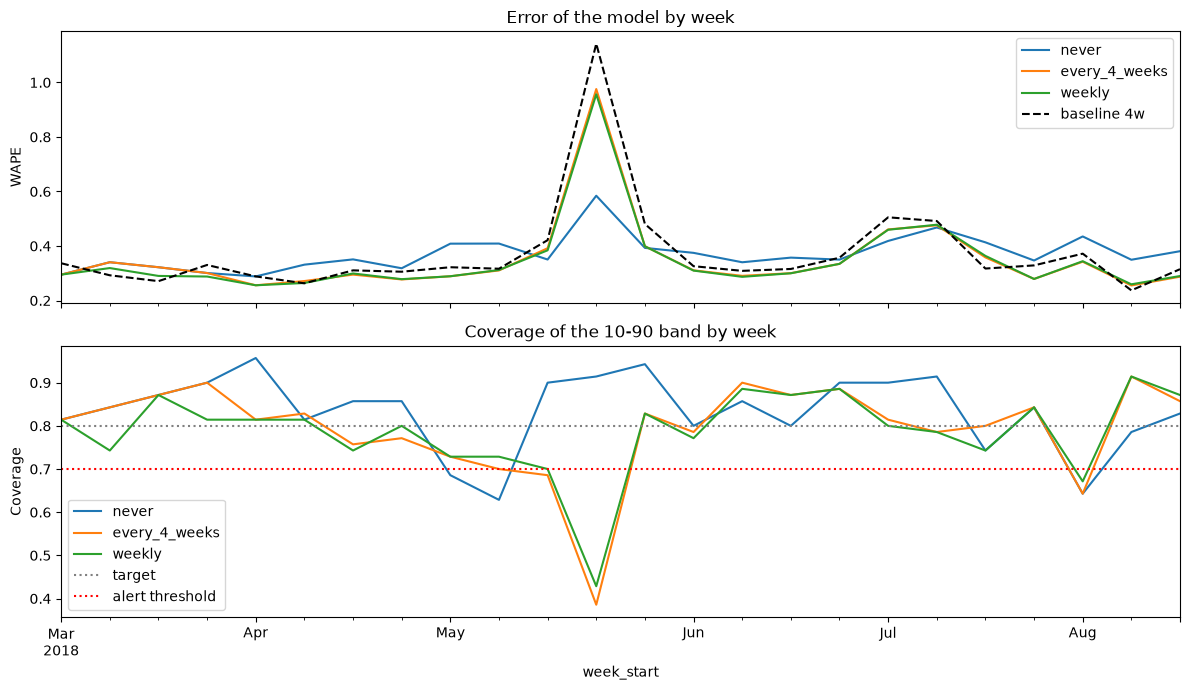

In [3]:
order = list(STRATEGIES)
wape_by_week = results.pivot(index="week_start", columns="strategy", values="wape_model")[order]
coverage_by_week = results.pivot(index="week_start", columns="strategy", values="coverage")[order]
baseline_by_week = results[results["strategy"] == "never"].set_index("week_start")["wape_baseline"]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
wape_by_week.plot(ax=axes[0])
baseline_by_week.plot(ax=axes[0], color="black", linestyle="--", label="baseline 4w")
axes[0].set_ylabel("WAPE")
axes[0].set_title("Error of the model by week")
axes[0].legend()

coverage_by_week.plot(ax=axes[1])
axes[1].axhline(0.8, color="gray", linestyle=":", label="target")
axes[1].axhline(0.7, color="red", linestyle=":", label="alert threshold")
axes[1].set_ylabel("Coverage")
axes[1].set_title("Coverage of the 10-90 band by week")
axes[1].legend()
plt.tight_layout()
plt.show()

### Effect of the age of the model

The model that is never retrained, grouped in blocks of four weeks since its training.

In [4]:
never = results[results["strategy"] == "never"].copy()
never["weeks_since_training"] = never["model_age_weeks"] // 4 * 4
by_age = never.groupby("weeks_since_training")[["abs_error_model", "abs_error_baseline", "units", "inside", "n"]].sum()
pd.DataFrame({
    "wape_model": by_age["abs_error_model"] / by_age["units"],
    "wape_baseline": by_age["abs_error_baseline"] / by_age["units"],
    "coverage": by_age["inside"] / by_age["n"],
}).round(3).reset_index()

,weeks_since_training,wape_model,wape_baseline,coverage
0,0,0.315,0.307,0.857
1,4,0.324,0.292,0.871
2,8,0.418,0.452,0.782
3,12,0.365,0.350,0.850
4,16,0.410,0.403,0.864
5,20,0.381,0.315,0.775


## Part 3. Alerts

A week raises an alert when the error of the model is more than 1.25 times its error on its own calibration window, or when the coverage of the band is below 70%. Each week has 70 category days, so the coverage of a single week is noisy and some alerts are expected by chance.

In [5]:
alerts = results.groupby("strategy", sort=False)[["alert_error", "alert_coverage", "alert"]].sum().astype(int)
alerts["weeks"] = results.groupby("strategy", sort=False).size()
alerts.reset_index()

,strategy,alert_error,alert_coverage,alert,weeks
0,never,2,3,5,24
1,every_4_weeks,4,3,5,24
2,weekly,2,2,3,24


In [6]:
results[results["alert"]][["strategy", "week_start", "model_age_weeks", "wape_model", "reference_wape", "coverage"]].round(3)

,strategy,week_start,model_age_weeks,wape_model,reference_wape,coverage
8,never,2018-05-02,8,0.409,0.370,0.686
9,never,2018-05-09,9,0.409,0.370,0.629
11,never,2018-05-23,11,0.584,0.370,0.914
18,never,2018-07-11,18,0.468,0.370,0.914
21,never,2018-08-01,21,0.435,0.370,0.643
34,every_4_weeks,2018-05-16,2,0.392,0.271,0.686
35,every_4_weeks,2018-05-23,3,0.976,0.271,0.386
41,every_4_weeks,2018-07-04,1,0.461,0.366,0.814
42,every_4_weeks,2018-07-11,2,0.476,0.366,0.786
45,every_4_weeks,2018-08-01,1,0.342,0.358,0.643


## Findings

A model that is never retrained ends up worse than the simple baseline over the 24 weeks, with a WAPE of 0.368 against 0.351, and its decisions cost 4.6% more than the baseline with a calibrated buffer. Retraining every four weeks brings the error to 0.333 and the cost 5.1% below that buffered baseline, and retraining every week gives 0.330 and 5.4%. Retraining every week adds little over every four weeks, which keeps most of the benefit with a quarter of the retrainings. Weekly retraining gives 0.330 on these days, close to the 0.324 of the backtest on the same days.

The model that is never retrained has a higher error than the baseline in five of the six blocks of four weeks, and its error does not rise steadily with its age. Its band covers 83% of the days, above the 80% target, while its error is the highest of the three, so the coverage alone would not reveal that the model has aged.

The simple alerts do not separate an old model from a fresh one. The model that is never retrained raises alerts in 5 of the 24 weeks, the one retrained every four weeks in 5 and the one retrained every week in 3. The week of 2018-05-23 raises an alert in the three strategies, with an error between 0.58 and 0.98, so it points to a shock in demand and not to an old model, although the cause was not checked against other data. The coverage of a single week of 70 category days moves between 0.39 and 0.91 in the weeks that raised alerts, so a threshold on one week is too noisy. A rule that needs several weeks in a row would be more useful.

This is a replay of 24 weeks of past data with assumed costs, so it shows how the monitoring would work and not how a deployed one would perform.